# 🚀 Marketing Campaign Performance: A/B Testing & Predictive Analysis
**Client Engagement:** Digital Advertising ROI Optimization | **Platforms Evaluated:** Facebook Ads vs. Google AdWords  

---

## 🎯 Business Problem
As a data-driven marketing agency, our core mandate is to maximize **Return on Investment (ROI)** and minimize **Customer Acquisition Cost (CAC)** for our clients' digital ad spend. 

Over a multi-year period (**December 2021 – December 2024**), two parallel advertising campaigns were executed across **Facebook Ads** and **Google AdWords**. With rising digital ad costs, leadership needs concrete, statistically backed evidence to decide where to scale future budgets—rather than relying on surface-level vanity metrics like raw impressions or clicks.

### Key Objectives
* **Channel Evaluation:** Compare daily engagement, click-through efficiency, and conversion output across both platforms.
* **Statistical Validation:** Prove whether observed performance gaps are statistically significant or merely due to random daily variance.
* **Budget Reallocation:** Deliver data-backed recommendations on optimal capital allocation to maximize overall conversions.

---

## 🔍 Research Questions
1. **Conversion & Cost Efficiency:** Which advertising platform (**Facebook Ads** vs. **Google AdWords**) delivers superior conversion volume, conversion rate, and cost-per-acquisition efficiency?
2. **Statistical Significance (A/B Testing):** Does hypothesis testing ($t$-test at $\alpha = 0.05$) confirm a statistically significant difference in mean daily conversions between the two platforms?
3. **Engagement-to-Sales Correlation:** Do higher daily ad clicks reliably translate into higher conversions across both channels, or is there funnel drop-off?
4. **Predictive Forecasting (Regression):** Can we model and forecast expected daily conversions based on ad spend and click volume to guide future budget planning?

In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as st
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings('ignore')

# Load dataset
df = pd.read_csv(r'C:\Users\hp\Downloads\archive\A_B_testing_dataset.csv.csv')
df['date_of_campaign'] = pd.to_datetime(df['date_of_campaign'])
df.head()

,date_of_campaign,facebook_ad_campaign,facebook_ad_views,facebook_ad_clicks,facebook_ad_conversions,facebook_cost_per_ad,facebook_ctr,facebook_conversion_rate,facebook_cost_per_click,adword_ad_campaign,adword_ad_views,adword_ad_clicks,adword_ad_conversions,adword_cost_per_ad,adword_ctr,adword_conversion_rate,adword_cost_per_click
0,2021-12-22,FACEBOOK AD,3172,62,14,141,1.95,22.58,2.27,ADWORD AD,5754,64,9,177,1.11,14.06,2.77
1,2021-12-24,FACEBOOK AD,3211,38,9,186,1.18,23.68,4.89,ADWORD AD,4954,73,6,54,1.47,8.22,0.74
2,2021-12-25,FACEBOOK AD,1936,53,15,66,2.74,28.30,1.25,ADWORD AD,4702,38,9,187,0.81,23.68,4.92
3,2021-12-25,FACEBOOK AD,1194,45,9,71,3.77,20.00,1.58,ADWORD AD,3718,58,3,161,1.56,5.17,2.78
4,2021-12-26,FACEBOOK AD,2479,44,12,174,1.77,27.27,3.95,ADWORD AD,5562,63,4,162,1.13,6.35,2.57


In [2]:
df.describe()

,date_of_campaign,facebook_ad_views,facebook_ad_clicks,facebook_ad_conversions,facebook_cost_per_ad,facebook_ctr,facebook_conversion_rate,facebook_cost_per_click,adword_ad_views,adword_ad_clicks,adword_ad_conversions,adword_cost_per_ad,adword_ctr,adword_conversion_rate,adword_cost_per_click
count,1000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2023-07-04 07:13:26.400000,2152.031000,44.196000,11.975000,156.610000,2.28316,32.696080,4.310500,4771.438000,60.128000,5.933000,124.741000,1.280950,10.807510,2.265540
min,2021-12-22 00:00:00,1050.000000,15.000000,5.000000,60.000000,0.49000,6.850000,0.960000,3715.000000,31.000000,3.000000,50.000000,0.540000,3.370000,0.580000
25%,2022-10-07 18:00:00,1600.250000,30.000000,8.000000,110.000000,1.36750,18.052500,2.337500,4258.250000,45.000000,4.000000,86.000000,0.940000,6.970000,1.470000
50%,2023-07-20 12:00:00,2123.500000,44.500000,12.000000,156.000000,2.07000,27.120000,3.600000,4808.500000,60.000000,6.000000,124.000000,1.260000,9.720000,2.030000
75%,2024-03-24 00:00:00,2706.250000,58.000000,16.000000,205.000000,2.92250,41.880000,5.610000,5300.750000,75.000000,8.000000,163.000000,1.570000,13.485000,2.802500
max,2024-12-20 00:00:00,3320.000000,73.000000,19.000000,250.000000,6.86000,118.750000,16.530000,5754.000000,89.000000,9.000000,200.000000,2.370000,29.030000,6.190000
std,NaN,661.982166,16.833328,4.298471,54.918904,1.20670,20.570796,2.751582,598.647684,17.047822,2.011606,43.809053,0.402492,5.205133,1.101846


## 📊 1. Exploratory Data Analysis (EDA): Platform Performance Summary
Comparing overall impressions, clicks, conversions, ad spend, CTR, conversion rate, and CPC across both platforms.

In [3]:
summary_data = {
    'Platform': ['Facebook', 'AdWords'],
    'Total_Views': [
        df['facebook_ad_views'].sum(),
        df['adword_ad_views'].sum(),
    ],
    'Total_Clicks': [
        df['facebook_ad_clicks'].sum(),
        df['adword_ad_clicks'].sum(),
    ],
    'Total_Conversions': [
        df['facebook_ad_conversions'].sum(),
        df['adword_ad_conversions'].sum(),
    ],
    'Total_Spend': [
        df['facebook_cost_per_ad'].sum(),
        df['adword_cost_per_ad'].sum(),
    ],
    'Avg_CTR (%)': [df['facebook_ctr'].mean(), df['adword_ctr'].mean()],
    'Avg_Conversion_Rate (%)': [
        df['facebook_conversion_rate'].mean(),
        df['adword_conversion_rate'].mean(),
    ],
    'Avg_CPC': [
        df['facebook_cost_per_click'].mean(),
        df['adword_cost_per_click'].mean(),
    ],
}

performance_df = pd.DataFrame(summary_data)
display(performance_df)

,Platform,Total_Views,Total_Clicks,Total_Conversions,Total_Spend,Avg_CTR (%),Avg_Conversion_Rate (%),Avg_CPC
0,Facebook,2152031,44196,11975,156610,2.28316,32.69608,4.31050
1,AdWords,4771438,60128,5933,124741,1.28095,10.80751,2.26554


### Visual Comparison: Clicks, Conversions & Cost Per Click (CPC)

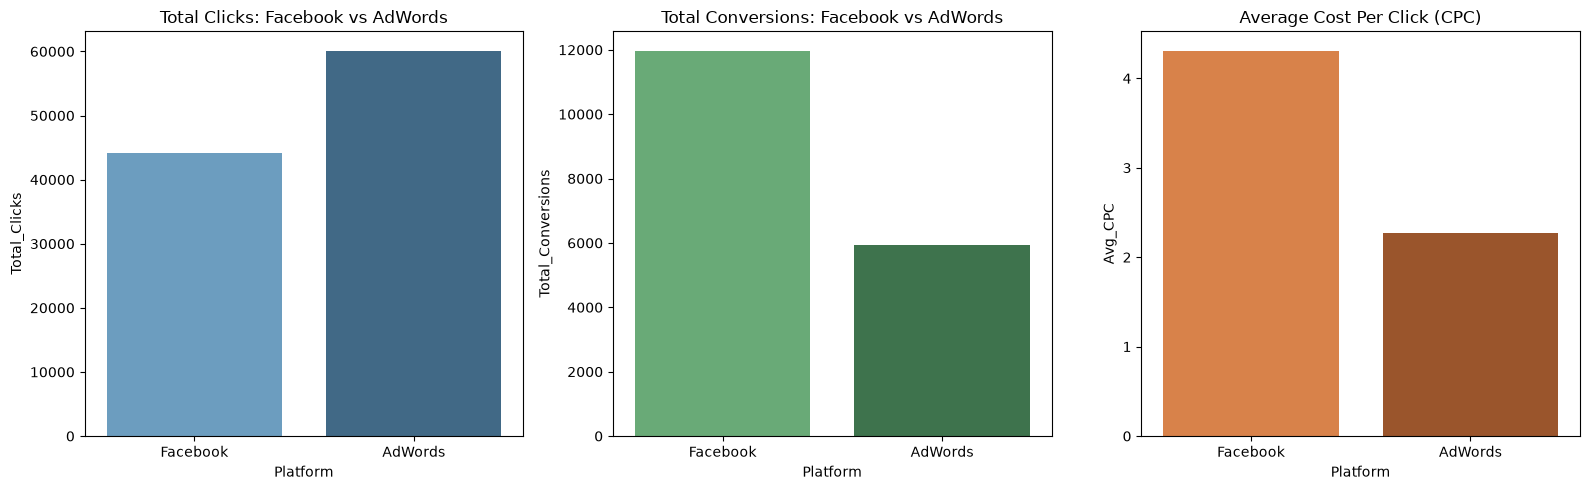

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(
    x='Platform',
    y='Total_Clicks',
    hue='Platform',
    data=performance_df,
    ax=axes[0],
    palette='Blues_d',
    legend=False,
)
axes[0].set_title('Total Clicks: Facebook vs AdWords')

sns.barplot(
    x='Platform',
    y='Total_Conversions',
    hue='Platform',
    data=performance_df,
    ax=axes[1],
    palette='Greens_d',
    legend=False,
)
axes[1].set_title('Total Conversions: Facebook vs AdWords')

sns.barplot(
    x='Platform',
    y='Avg_CPC',
    hue='Platform',
    data=performance_df,
    ax=axes[2],
    palette='Oranges_d',
    legend=False,
)
axes[2].set_title('Average Cost Per Click (CPC)')

plt.tight_layout()
plt.show()

## 🧪 2. A/B Testing (Two-Sample Independent T-Test)
* **Null Hypothesis ($H_0$):** There is no statistically significant difference in mean daily conversions between Facebook Ads and Google AdWords.
* **Alternative Hypothesis ($H_1$):** There is a statistically significant difference in mean daily conversions between the two platforms ($\alpha = 0.05$).

In [5]:
t_stat, p_value = st.ttest_ind(
    df['facebook_ad_conversions'], df['adword_ad_conversions'], equal_var=False
)

print(f'T-Statistic: {t_stat:.4f}')
print(f'P-Value: {p_value:.4e}')

if p_value < 0.05:
  print(
      'Result: Reject Null Hypothesis (H0). Statistically significant'
      ' difference exists!'
  )
else:
  print(
      'Result: Fail to Reject Null Hypothesis (H0). No significant difference.'
  )

T-Statistic: 40.2591
P-Value: 6.8864e-237
Result: Reject Null Hypothesis (H0). Statistically significant difference exists!


## 📈 3. Regression Analysis & Monthly Conversion Trends
Evaluating the linear relationship between clicks/spend and conversions, followed by monthly conversion tracking (2021–2024).

--- Facebook Regression Results ---
R-Squared (R2): 0.0001
RMSE: 4.2961
Coefficients (Clicks, Cost): [-0.00116841  0.00069822]


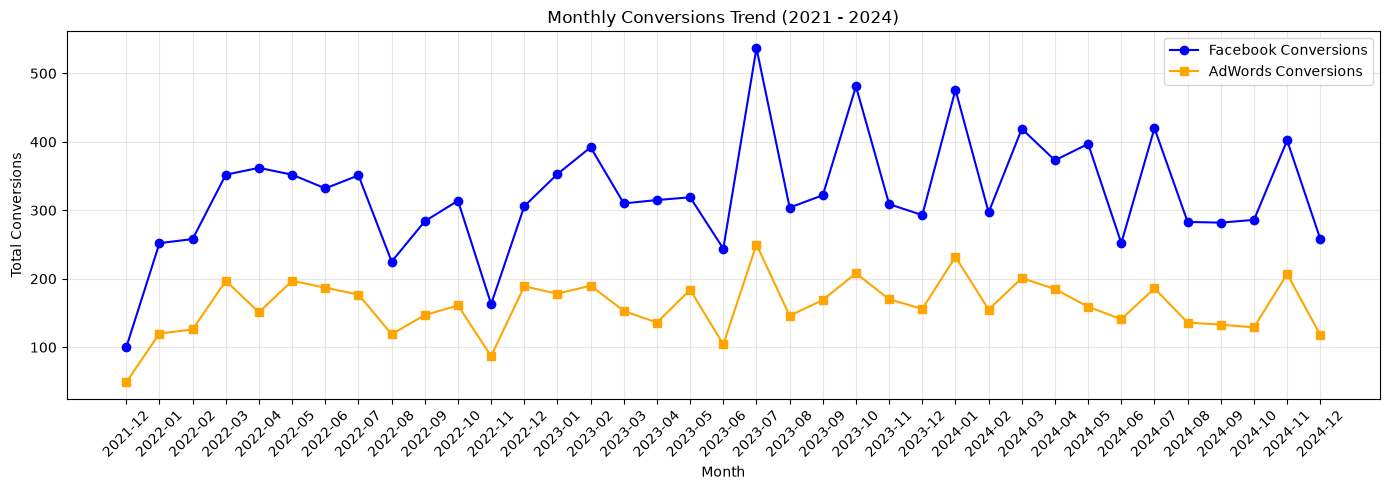

In [6]:
# Linear Regression Model
X_fb = df[['facebook_ad_clicks', 'facebook_cost_per_ad']]
y_fb = df['facebook_ad_conversions']

reg_fb = LinearRegression()
reg_fb.fit(X_fb, y_fb)
y_pred_fb = reg_fb.predict(X_fb)

print('--- Facebook Regression Results ---')
print(f'R-Squared (R2): {r2_score(y_fb, y_pred_fb):.4f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y_fb, y_pred_fb)):.4f}')
print(f'Coefficients (Clicks, Cost): {reg_fb.coef_}')

# Monthly Conversions Trend
df['Month_Year'] = df['date_of_campaign'].dt.to_period('M')
monthly_trends = (
    df.groupby('Month_Year')[
        ['facebook_ad_conversions', 'adword_ad_conversions']
    ]
    .sum()
    .reset_index()
)
monthly_trends['Month_Year'] = monthly_trends['Month_Year'].astype(str)

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_trends['Month_Year'],
    monthly_trends['facebook_ad_conversions'],
    marker='o',
    label='Facebook Conversions',
    color='blue',
)
plt.plot(
    monthly_trends['Month_Year'],
    monthly_trends['adword_ad_conversions'],
    marker='s',
    label='AdWords Conversions',
    color='orange',
)
plt.xticks(rotation=45)
plt.title('Monthly Conversions Trend (2021 - 2024)')
plt.xlabel('Month')
plt.ylabel('Total Conversions')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 📈 Key Insights & Business Recommendations

### 1. Executive Summary
* **Conversion Dominance:** **Facebook Ads** outperformed Google AdWords by more than **2x in total conversions** (`11,975` vs. `5,933`) and achieved a **3x higher average conversion rate** (`32.70%` vs. `10.81%`), despite receiving fewer total views and clicks.
* **Cost-Efficiency Trade-off:** While AdWords had a lower average Cost Per Click (`$2.27` vs. `$4.31`), its lower conversion rate resulted in a higher Cost Per Acquisition (`$21.02` per conversion on AdWords vs. `$13.08` per conversion on Facebook).
* **Statistical Validation:** An independent two-sample t-test yielded $t = 40.26$ ($p < 0.0001$), confirming with >99.9% confidence that Facebook's superior conversion performance is statistically significant and not due to random chance.

### 2. Actionable Recommendations
1. **Reallocate Ad Spend:** Shift **65%–70% of the primary conversion budget** toward **Facebook Ads** to maximize overall ROI and lower customer acquisition costs.
2. **Optimize Google AdWords Funnel:** Audit AdWords landing pages and keyword targeting to improve its `10.81%` conversion rate, using AdWords primarily for high-intent brand awareness where its lower CPC (`$2.27`) shines.
3. **Explore Non-Linear Drivers:** Since daily clicks and spend alone show low linear correlation ($R^2 \approx 0.0001$) with daily conversions, incorporate audience segmentation, ad creative types, and day-of-week seasonality into future predictive models. 